# Проверка SVD данных без обучения сети

POD строится **только на train**; для A,n берём одну строку на среду. Сравниваем полное и randomized SVD в mass-lumped норме. Validation-кривые реконструкции считаем в consistent комплексной FEM L2 норме. Test здесь не используется.

Для $W=\operatorname{diag}(M\mathbf1)$ разлагаем $(X-\bar X)W^{1/2}=U\Sigma V^T$, сохраняем $\Phi=W^{-1/2}V_r$. Тогда $\Phi^TW\Phi=I$. Энергия делится на энергию **всей** центрированной матрицы, включая хвост за вычисленным рангом. Знаки отдельных SVD-векторов не сравниваем: используем principal angles.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
BASE = ROOT / 'neural_operator'
DATA_DIR = BASE / 'data' / 'low_frequency'
RUNS = BASE / 'runs' / 'low_frequency'
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.data import load_dataset
from neural_operator.plotting import display_table, plot_prediction, plot_history


In [2]:
from neural_operator.diagnostics import svd_diagnostics, transfer_diagnostics, write_csv
from neural_operator.plotting import plot_svd
dataset = load_dataset(DATA_DIR)
OUT = BASE / 'runs' / 'svd_diagnostics'
MAX_RANK = 96
summary, curves, spectra = svd_diagnostics(dataset, OUT, max_rank=MAX_RANK, seed=42)
display_table(summary)


field,method,snapshots,algorithm_used,computed_rank,seconds,orthogonality_fro,retained_centered_energy,snapshot_array_bytes,mode_array_bytes,largest_subspace_angle_degrees,singular_error_relative_to_leading
A,full,32,full,24,0.0038936,7.2526e-15,1,824576,618432,,
A,randomized,32,full,24,0.0030237,7.2526e-15,1,824576,618432,1.2778e-13,0
n,full,32,full,24,0.0034237,6.8544e-15,1,824576,618432,,
n,randomized,32,full,24,0.0030125,6.8544e-15,1,824576,618432,1.5518e-13,0
real,full,128,full,96,0.033728,2.398e-14,1,3298304,2473728,,
real,randomized,128,randomized,96,0.059474,2.3282e-14,1,3298304,2473728,0.091715,3.7397e-10
imag,full,128,full,96,0.031986,2.5289e-14,1,3298304,2473728,,
imag,randomized,128,randomized,96,0.058418,2.4577e-14,1,3298304,2473728,0.019193,4.9757e-11


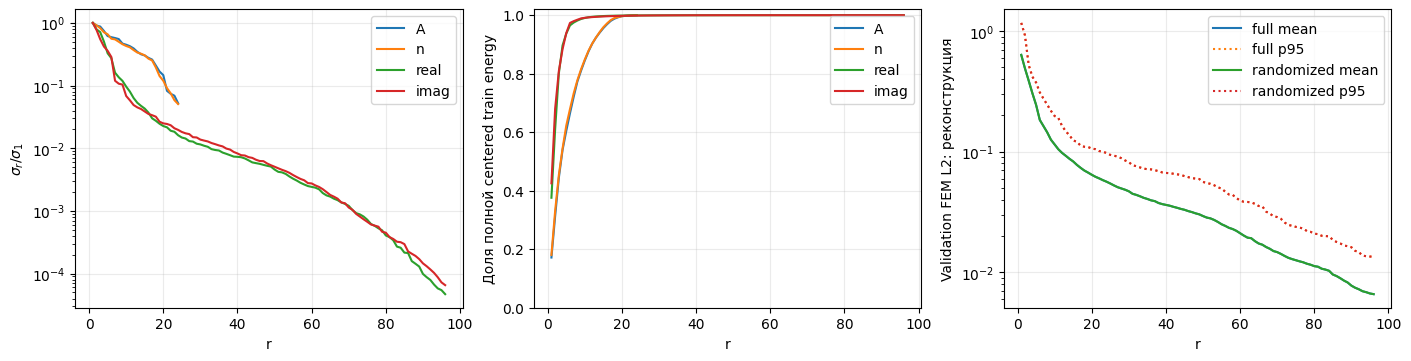

method,rank,mean,p95,target_attained
full,85,0.0096225,0.018611,True
randomized,85,0.0096225,0.018611,True


In [3]:
figure = plot_svd(curves, spectra)
figure.savefig(OUT / 'svd_diagnostics.png', dpi=160)
plt.show()
threshold = .01
recommendations = []
for method in ['full', 'randomized']:
    rows = [r for r in curves if r['method'] == method]
    adequate = [r for r in rows if r['mean_fem_l2'] <= threshold]
    best = adequate[0] if adequate else rows[-1]
    recommendations.append({'method': method, 'rank': best['rank'], 'mean': best['mean_fem_l2'],
                            'p95': best['p95_fem_l2'], 'target_attained': bool(adequate)})
display_table(recommendations)


## Ошибка FEM → grid → FEM

Для FNO используем равномерную сетку, для Chebyshev — узлы Lobatto. Перенос использует исходные FEM-треугольники. Таблица показывает ошибку одной интерполяции; это не ошибка нейросети и не строгая нижняя граница достижимой ошибки. Память в SVD-таблице — размер хранимых массивов, а не peak RAM BLAS.


In [4]:
transfer_rows = transfer_diagnostics(dataset, resolution=32)
display_table(transfer_rows)
write_csv(OUT / 'transfer_validation.csv', transfer_rows)


grid,resolution,field,mean_fem_l2,p95_fem_l2
uniform,32,A,0.010697,0.013338
uniform,32,n,0.047077,0.05928
uniform,32,u_scat,0.026658,0.037529
chebyshev,32,A,0.016815,0.020538
chebyshev,32,n,0.072537,0.097186
chebyshev,32,u_scat,0.040425,0.051961


Training по умолчанию ограничивает POD ранг 48 для небольшого локального эксперимента и явно сообщает, если цель 1% на validation недостижима. Чтобы проверить другой ранг, измените TrainConfig и каталог запуска; test не используйте для подбора. Mass-lumped проекция не является оптимальной consistent FEM-проекцией на этот span. Обоснование и источники: [docs/methods.md](docs/methods.md), [docs/references.md](docs/references.md).
